# Carbonation data audit and model credibility check
**Purpose.** Decide whether a √t carbonation model built on this dataset is credible enough to feed a later carbon–strength optimization. This notebook does **not** estimate CO₂ uptake or lifecycle carbon.

**Inputs (same folder):** `carbonation_long.csv` (353 rows, 48 columns)`carbonation_long.xlsx` (sheet `Mixes`, one row per mix, with my corrections in the blue `*_USED` columns).

**Plan**
1. Fit xc = k√t per series (mix × sheltered/unsheltered) and test whether √t is a fair description.
2. Compare k across mix types.
3. Re-run with C18 as slag instead of fly ash.
4. Test how much w/b and curing time explain.
5. Report uncertainty. No causal claim about fly ash alone.

**Unit of analysis.** Each series has 3–4 points, so each *mix* gives one k per condition. With 45 mixes, mix-level n is the real sample size, not 353 rows.

In [1]:
import pandas as pd, numpy as np, warnings
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf, statsmodels.api as sm
from scipy import stats
warnings.filterwarnings('ignore')
pd.set_option('display.width',200); pd.set_option('display.max_columns',50)
plt.rcParams.update({'figure.dpi':110,'font.size':9,'axes.spines.top':False,'axes.spines.right':False})

# Load from canonical carbonation_master.csv
df_master = pd.read_csv('carbonation_master.csv')

D = df_master.copy()
D['x'] = D['carbonation_depth_mm']
D['t'] = D['exposure_time_years']
D['condition'] = D['exposure_condition'].str.lower()
D['curing_days_dataset'] = D['curing_time_days']

mix_cols = [
    'mix_id', 'notation', 'wb_ratio', 'binder_content_kg_m3', 'sand_kg_m3', 'gravel_kg_m3',
    'air_content_pct', 'fc_28d_mpa', 'curing_days_USED', 'curing_time_days', 'scm1_type', 'scm1_pct',
    'scm2_type', 'scm2_pct', 'total_scm_pct', 'opc_kg_m3', 'water_kg_m3', 'scm_group'
]
Mx = D[mix_cols].drop_duplicates('mix_id').rename(columns={
    'wb_ratio': 'w_b',
    'binder_content_kg_m3': 'binder_kg_m3',
    'air_content_pct': 'air_pct',
    'fc_28d_mpa': 'fc_28d_MPa',
    'scm1_type': 'scm1_type_USED',
    'scm1_pct': 'scm1_pct_USED',
    'total_scm_pct': 'scm_total_pct',
    'opc_kg_m3': 'clinker_kg_m3',
    'curing_time_days': 'curing_days_dataset'
}).reset_index(drop=True)

# casting batches from Vu et al. 2019, Table 5 (used only to cluster the uncertainty)
T5={'B1':'C4,C7,C8','B2':'C1,C2,C3,C5','B3':'C6,C9,C10,C11','B4':'C14,C15,C16','B5':'C12,C21,C32','B6':'C25,C26,C27','B7':'C36,C37,C38','B8':'C42,C45','B9':'C13,C17,C19,C20','B10':'C22,C23,C24,C28','B11':'C29,C30,C18,C31','B12':'C33,C34,C35,C39','B13':'C40,C41,C43,C44'}
bm={m:b for b,ids in T5.items() for m in ids.split(',')}
GRP_ORDER=['OPC_only','LS','SgF','FaV','PoM','Ternary']
COL={'OPC_only':'#444','LS':'#c9a227','SgF':'#2a7ab0','FaV':'#d2691e','PoM':'#7a4fa3','Ternary':'#2e8b57'}
print('Master Dataset Loaded:', D.shape, D.mix_id.nunique(),'mixes;', D.groupby('condition').size().to_dict())


Master Dataset Loaded: (353, 52) 45 mixes; {'sheltered': 167, 'unsheltered': 186}


## 1. Data audit recap

In [2]:
print('Rows per measurement campaign and condition:')
print(D.pivot_table(index='campaign_year',columns='condition',values='x',aggfunc='size'))
print()
print('Row flags:'); print(D['flags'].fillna('').str.split(';').explode().replace('', 'none').value_counts().to_string())
print()
print('Series length (points per mix x condition):'); print(D.groupby(['mix_id','condition']).size().value_counts().sort_index().to_string())
print()
print('Curing days used (min / median / max) by SCM group:')
print(Mx.groupby('scm_group').curing_days_USED.agg(['min','median','max','count']).loc[GRP_ORDER])

Rows per measurement campaign and condition:
condition      sheltered  unsheltered
campaign_year                        
2012                  14           14
2014                  45           45
2016                  45           45
2020                  25           40
2022                  38           42

Row flags:
flags
none            310
COARSE_1Y        28
PAPER_DIFF        9
NONMONOTONIC      6
SD_ZERO           1

Series length (points per mix x condition):
2     1
3    15
4    64
5    10

Curing days used (min / median / max) by SCM group:
           min  median  max  count
scm_group                         
OPC_only    49    97.0  104      8
LS           7    41.0   90      8
SgF          7    27.0   29     10
FaV          7    28.0   30     11
PoM         22    22.0   28      5
Ternary     19    22.0   23      3


The audit points that matter for modelling (full list in the `Issues` sheet of the workbook):
- 28 one-year values are rounded to 0.5 mm → tested by dropping them in the sensitivity runs below.
- C18 (slag vs fly ash), 8 curing times, C45 replacement %: resolved by comparing with the 2019 paper; each is tested as a sensitivity.
- Strength and w/b come from one source family, so agreement with the 2019 paper is a transcription check, not independent verification.

## 2. Step 1: fit xc = k·√t per series

In [3]:
def k_series(df,intercept=False):
    out=[]
    for (m,c),g in df.groupby(['mix_id','condition']):
        s=np.sqrt(g.t.values); x=g.x.values; n=len(x)
        if intercept and n>=3:
            A=np.c_[np.ones_like(s),s]; b=np.linalg.lstsq(A,x,rcond=None)[0]; k=b[1]; res=x-A@b; dof=n-2
            se=np.sqrt((res**2).sum()/dof*np.linalg.inv(A.T@A)[1,1])
        else:
            k=(s*x).sum()/(s*s).sum(); res=x-k*s; dof=n-1
            se=np.sqrt((res**2).sum()/dof/(s*s).sum()) if dof>0 else np.nan
        out.append((m,c,k,se,n,np.sqrt((res**2).sum()/dof) if dof>0 else np.nan))
    return pd.DataFrame(out,columns=['mix_id','condition','k','se','n','rmse_mm'])
K=k_series(D)
K['rel_se']=K.se/K.k
print(K.groupby('condition').agg(n_series=('k','size'),k_median=('k','median'),k_min=('k','min'),k_max=('k','max'),
      rmse_median_mm=('rmse_mm','median'),rel_se_median=('rel_se','median')).round(2))
print('\nk units: mm / year^0.5')

             n_series  k_median  k_min  k_max  rmse_median_mm  rel_se_median
condition                                                                   
sheltered          45      3.19   1.60   8.85            0.73           0.05
unsheltered        45      2.65   1.33   7.04            0.67           0.05

k units: mm / year^0.5


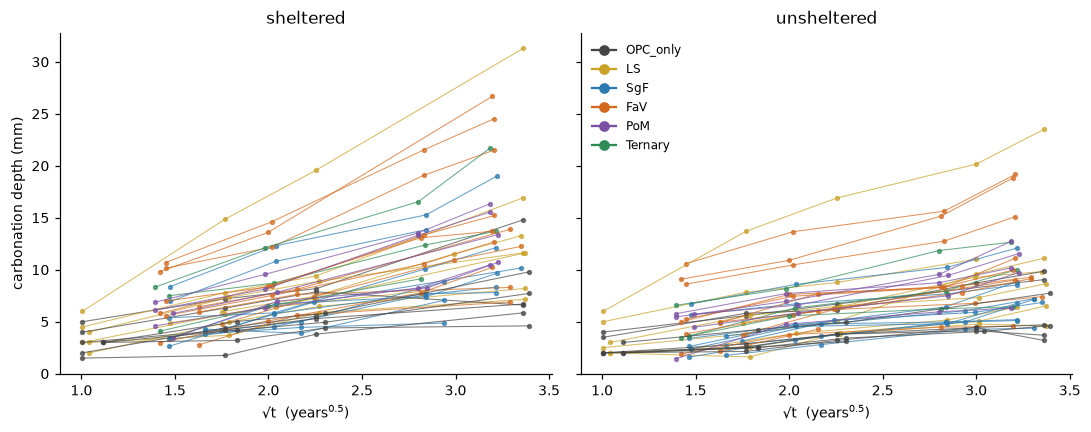

In [4]:
fig,ax=plt.subplots(1,2,figsize=(10,4),sharey=True)
G=Mx.set_index('mix_id').scm_group
for a,c in zip(ax,['sheltered','unsheltered']):
    for m,g in D[D.condition==c].groupby('mix_id'):
        a.plot(np.sqrt(g.t),g.x,'-o',ms=2.5,lw=.7,alpha=.7,color=COL[G[m]])
    a.set_title(c); a.set_xlabel('√t  (years$^{0.5}$)')
ax[0].set_ylabel('carbonation depth (mm)')
h=[plt.Line2D([],[],color=COL[g],marker='o',label=g) for g in GRP_ORDER]; ax[1].legend(handles=h,frameon=False,fontsize=8)
plt.tight_layout(); plt.show()

### Is √t a fair description? Four checks

In [5]:
D['lx']=np.log(D.x); D['lt']=np.log(D.t)
print('(a) Free exponent n in x = k t^n (series fixed effects, errors clustered by mix). √t means n = 0.5')
for lab,df in [('all rows',D),('excluding coarse 1-yr rows',D[D.campaign_year!=2012])]:
    for c,g in df.groupby('condition'):
        m=smf.ols('lx ~ lt + C(mix_id)',data=g).fit(cov_type='cluster',cov_kwds={'groups':g.mix_id})
        print(f'  {lab:28s}{c:12s} n = {m.params["lt"]:.3f}  95% CI [{m.conf_int().loc["lt",0]:.3f}, {m.conf_int().loc["lt",1]:.3f}]')

(a) Free exponent n in x = k t^n (series fixed effects, errors clustered by mix). √t means n = 0.5
  all rows                    sheltered    n = 0.509  95% CI [0.458, 0.560]
  all rows                    unsheltered  n = 0.452  95% CI [0.406, 0.498]
  excluding coarse 1-yr rows  sheltered    n = 0.533  95% CI [0.488, 0.579]
  excluding coarse 1-yr rows  unsheltered  n = 0.490  95% CI [0.432, 0.547]


In [6]:
print('(b) Mean relative residual of the √t fit by campaign (a systematic curve would show a trend)')
D2=D.merge(K[['mix_id','condition','k']],on=['mix_id','condition'])
D2['rel']=(D2.x-D2.k*np.sqrt(D2.t))/(D2.k*np.sqrt(D2.t))
print(D2.pivot_table(index='campaign_year',columns='condition',values='rel',aggfunc='mean').round(3))
print()
print('(c) Out-of-sample: fit k using campaigns up to 2016 only, predict 2020 and 2022')
rows=[]
for (m,c),g in D.groupby(['mix_id','condition']):
    tr=g[g.campaign_year<=2016]; te=g[g.campaign_year>=2020]
    if len(tr)>=2 and len(te):
        s=np.sqrt(tr.t.values); k=(s*tr.x.values).sum()/(s*s).sum()
        for _,r in te.iterrows(): rows.append((c,r.campaign_year,r.x,k*np.sqrt(r.t)))
O=pd.DataFrame(rows,columns=['condition','yr','obs','pred']); O['err']=O.obs-O.pred; O['rel']=O.err/O.pred
print(O.groupby(['condition','yr']).agg(n=('err','size'),bias_mm=('err','mean'),rmse_mm=('err',lambda s:np.sqrt((s**2).mean())),mean_rel_err=('rel','mean')).round(2))

(b) Mean relative residual of the √t fit by campaign (a systematic curve would show a trend)
condition      sheltered  unsheltered
campaign_year                        
2012               0.085        0.219
2014              -0.029       -0.009
2016              -0.002        0.060
2020              -0.005       -0.027
2022               0.007       -0.011

(c) Out-of-sample: fit k using campaigns up to 2016 only, predict 2020 and 2022
                   n  bias_mm  rmse_mm  mean_rel_err
condition   yr                                      
sheltered   2020  25     0.33     1.10          0.04
            2022  38     0.55     1.92          0.03
unsheltered 2020  40    -0.72     1.39         -0.06
            2022  42    -0.49     1.46         -0.04


In [7]:
print('(d) Through-origin vs free intercept: does the choice change k?')
Ki=k_series(D,intercept=True)
cmp=K.merge(Ki,on=['mix_id','condition'],suffixes=('_origin','_free'))
cmp=cmp[cmp.n_origin>=3]
cmp['ratio']=cmp.k_free/cmp.k_origin
print(cmp.groupby('condition').ratio.describe()[['count','mean','50%','min','max']].round(2))

(d) Through-origin vs free intercept: does the choice change k?
             count  mean   50%   min   max
condition                                 
sheltered     45.0  1.03  1.07  0.40  1.42
unsheltered   44.0  0.92  0.90  0.53  1.34


**Reading step 1.** The exponent is statistically consistent with 0.5 once the coarse 1-year rows are excluded; unsheltered is slightly below 0.5 when they are included. Out-of-sample errors from extrapolating 2016 data to 2020–22 are a few percent on average, with RMSE of order 1–2 mm on depths of roughly 5–15 mm. So √t is an acceptable working form **for these exposure years in this climate**. It says nothing about much longer service lives or other climates.

## 3. Step 2: compare k across mix types

          n_mixes  k_sh_mean  k_sh_lo  k_sh_hi  k_un_mean  k_un_lo  k_un_hi  unsh/sh  mean_w/b  mean_curing_d  mean_SCM_%
group                                                                                                                    
OPC_only        8       2.47     2.00     3.07       1.88     1.48     2.35     0.76      0.54          81.62        0.00
LS              8       4.02     2.93     5.54       3.08     2.09     4.40     0.75      0.53          53.62       13.38
SgF            10       3.20     2.55     3.97       2.19     1.82     2.64     0.70      0.52          23.20       23.00
FaV            11       4.58     3.53     5.71       3.39     2.59     4.27     0.73      0.53          25.27       23.64
PoM             5       3.99     3.31     4.66       3.08     2.48     3.54     0.79      0.53          24.40       18.00
Ternary         3       4.63     3.19     6.33       3.11     2.24     4.14     0.68      0.50          21.33       40.00

Kruskal-Wallis across g

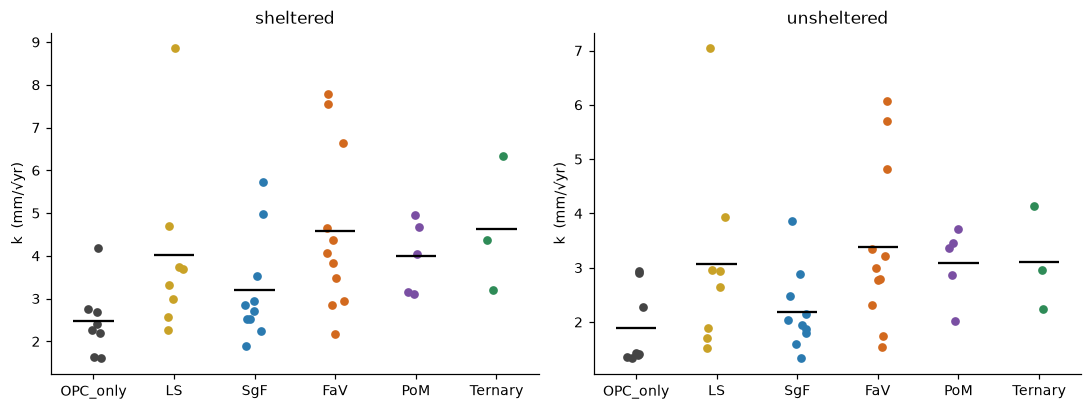

In [8]:
W=K.pivot(index='mix_id',columns='condition',values='k').rename(columns={'sheltered':'k_sh','unsheltered':'k_un'}).reset_index()
mix=Mx.merge(W,on='mix_id'); mix['ratio_un_sh']=mix.k_un/mix.k_sh
mix['grp']=mix.scm_group; mix['wb']=mix.w_b; mix['batch']=mix.mix_id.map(bm)
rng=np.random.default_rng(1)
def bci(v,B=4000):
    v=np.asarray(v); return np.percentile([rng.choice(v,len(v)).mean() for _ in range(B)],[2.5,97.5])
rows=[]
for g in GRP_ORDER:
    s=mix[mix.grp==g]; r={'group':g,'n_mixes':len(s)}
    for c in ['k_sh','k_un']:
        lo,hi=bci(s[c]); r[c+'_mean']=s[c].mean(); r[c+'_lo']=lo; r[c+'_hi']=hi
    r['unsh/sh']=s.ratio_un_sh.median(); r['mean_w/b']=s.wb.mean(); r['mean_curing_d']=s.curing_days_USED.mean(); r['mean_SCM_%']=s.scm_total_pct.mean()
    rows.append(r)
GT=pd.DataFrame(rows).set_index('group'); print(GT.round(2).to_string())
print('\nKruskal-Wallis across groups: sheltered p =',round(stats.kruskal(*[g.k_sh for _,g in mix.groupby('grp')]).pvalue,3),
      ' unsheltered p =',round(stats.kruskal(*[g.k_un for _,g in mix.groupby('grp')]).pvalue,3))
fig,ax=plt.subplots(1,2,figsize=(10,3.8),sharey=False)
for a,c in zip(ax,['k_sh','k_un']):
    for i,g in enumerate(GRP_ORDER):
        v=mix[mix.grp==g]; a.scatter(np.full(len(v),i)+rng.uniform(-.12,.12,len(v)),v[c],color=COL[g],s=22)
        a.hlines(v[c].mean(),i-.25,i+.25,color='k')
    a.set_xticks(range(6)); a.set_xticklabels(GRP_ORDER); a.set_title({'k_sh':'sheltered','k_un':'unsheltered'}[c]); a.set_ylabel('k  (mm/√yr)')
plt.tight_layout(); plt.show()

**Caution.** The group means above mix different w/b, replacement levels and curing times (see the last three columns). A raw group difference is **not** an SCM-type effect. The next two sections try to separate these.

### A closer (but still imperfect) comparison: the w/b 0.50, 310 kg/m³ series
Only here are w/b, binder content and air content nearly equal across SCM types.

In [9]:
ser=mix[(mix.wb==0.5)&(mix.binder_kg_m3==310)].sort_values(['scm_total_pct','grp'])
print(ser[['mix_id','notation','scm_total_pct','curing_days_USED','air_pct','fc_28d_MPa','k_sh','k_un']].round(2).to_string(index=False))
print('\nUncomfortable fact: the cement-only reference here (C5) was cured',int(ser.loc[ser.mix_id=="C5","curing_days_USED"].iloc[0]),'days; every SCM mix in this series was cured 19-29 days.')

mix_id               notation  scm_total_pct  curing_days_USED  air_pct  fc_28d_MPa  k_sh  k_un
    C5     CmS-NoSCM-0.50-310            0.0               104      2.0        48.7  2.41  1.35
   C13      CmS-11LS-0.50-310           11.0                29      1.8        48.5  2.98  1.88
   C33     CmS-15FaV-0.50-310           15.0                23      1.5        46.0  2.86  1.55
   C43     CmS-15PoM-0.50-310           15.0                22      1.4        43.4  3.16  2.02
   C22     CmS-15SgF-0.50-310           15.0                19      1.5        56.4  2.53  1.60
   C34     CmS-30FaV-0.50-310           30.0                23      1.3        37.5  4.38  3.21
   C44     CmS-30PoM-0.50-310           30.0                22      1.6        34.7  4.97  3.36
   C23     CmS-30SgF-0.50-310           30.0                19      1.4        55.7  2.53  1.80
   C28 CmS-20SgF20FaV-0.5-310           40.0                19      1.4        41.1  4.37  2.96
   C39 CmS-20SgF20PoM-0.5-310           

## 4. Step 4: how much do w/b and curing explain?

In [10]:
mix['lk_sh']=np.log(mix.k_sh); mix['lk_un']=np.log(mix.k_un)
mix['lc']=np.log2(mix.curing_days_USED)            # per doubling of curing days
mix['alpha']=mix.clinker_kg_m3/mix.water_kg_m3     # clinker / water, as in the 2019 paper's reasoning
mix['la']=np.log(mix.alpha)
for t in ['FaV','SgF','LS','PoM']: mix['p_'+t]=0.0
for i,r in mix.iterrows():
    if r.scm1_type_USED in ['FaV','SgF','LS','PoM']: mix.loc[i,'p_'+r.scm1_type_USED]+=r.scm1_pct_USED
    if isinstance(r.scm2_type,str) and r.scm2_type in ['FaV','SgF','LS','PoM']: mix.loc[i,'p_'+r.scm2_type]+=r.scm2_pct
for t in ['FaV','SgF','LS','PoM']: mix['q_'+t]=mix['p_'+t]/10   # per +10 percentage points of cement replaced
print(mix[['wb','curing_days_USED','alpha','scm_total_pct','air_pct','binder_kg_m3','fc_28d_MPa','k_sh','k_un']].corr().round(2))

                    wb  curing_days_USED  alpha  scm_total_pct  air_pct  binder_kg_m3  fc_28d_MPa  k_sh  k_un
wb                1.00              0.31  -0.52          -0.05    -0.59         -0.67       -0.31  0.57  0.61
curing_days_USED  0.31              1.00   0.27          -0.52     0.07         -0.37        0.01 -0.08  0.00
alpha            -0.52              0.27   1.00          -0.81     0.58          0.44        0.37 -0.79 -0.75
scm_total_pct    -0.05             -0.52  -0.81           1.00    -0.25         -0.05       -0.26  0.58  0.51
air_pct          -0.59              0.07   0.58          -0.25     1.00          0.56       -0.16 -0.46 -0.40
binder_kg_m3     -0.67             -0.37   0.44          -0.05     0.56          1.00       -0.16 -0.38 -0.35
fc_28d_MPa       -0.31              0.01   0.37          -0.26    -0.16         -0.16        1.00 -0.61 -0.70
k_sh              0.57             -0.08  -0.79           0.58    -0.46         -0.38       -0.61  1.00  0.96
k_un      

In [11]:
def loo_rmse(m):
    h=m.get_influence().hat_matrix_diag; return np.sqrt(((m.resid/(1-h))**2).mean())
def lobo_rmse(df,resp,form):
    err=[]
    for b in df.batch.unique():
        tr,te=df[df.batch!=b],df[df.batch==b]
        m=smf.ols(f'{resp} ~ {form}',data=tr).fit(); err+=list(te[resp]-m.predict(te))
    return np.sqrt(np.mean(np.square(err)))
forms={'constant only':'1',
 'type only':"C(grp,Treatment('OPC_only'))",
 'w/b + curing':'wb+lc',
 'type + w/b':"C(grp,Treatment('OPC_only'))+wb",
 'type + w/b + curing':"C(grp,Treatment('OPC_only'))+wb+lc",
 'clinker/water ratio':'la',
 'replacement % (total) + w/b + curing':'scm_total_pct+wb+lc',
 'replacement % by SCM (per 10 pts) + w/b':'q_FaV+q_SgF+q_LS+q_PoM+wb',
 'replacement % by SCM (per 10 pts) + w/b + curing':'q_FaV+q_SgF+q_LS+q_PoM+wb+lc'}
rows=[]
for resp,lab in [('lk_sh','sheltered'),('lk_un','unsheltered')]:
    for n,f in forms.items():
        m=smf.ols(f'{resp} ~ {f}',data=mix).fit()
        rows.append((lab,n,int(m.df_model)+1,m.rsquared_adj,loo_rmse(m),lobo_rmse(mix,resp,f)))
MC=pd.DataFrame(rows,columns=['condition','model','n_params','adj_R2','LOO_rmse(log k)','leave-one-batch-out_rmse(log k)'])
print(MC.round(3).to_string(index=False))
print('\nRMSE on log k of 0.15 is roughly a ±15% typical prediction error for an unseen mix.')

  condition                                            model  n_params  adj_R2  LOO_rmse(log k)  leave-one-batch-out_rmse(log k)
  sheltered                                    constant only         1   0.000            0.409                            0.415
  sheltered                                        type only         6   0.200            0.386                            0.429
  sheltered                                     w/b + curing         3   0.398            0.329                            0.372
  sheltered                                       type + w/b         7   0.639            0.268                            0.265
  sheltered                              type + w/b + curing         8   0.631            0.271                            0.289
  sheltered                              clinker/water ratio         2   0.673            0.241                            0.252
  sheltered             replacement % (total) + w/b + curing         4   0.718            0.230  

**Reading the comparison.** Type alone explains little. w/b plus curing alone is poor. The model with replacement level *by SCM* plus w/b is by far the best, including when whole casting batches are held out. Curing adds nothing visible.

In [12]:
form='q_FaV+q_SgF+q_LS+q_PoM+wb+lc'
def coef_table(df,resp):
    m=smf.ols(f'{resp} ~ {form}',data=df).fit(cov_type='HC3'); ci=m.conf_int(); p=m.params
    out=pd.DataFrame({'ratio':np.exp(p),'lo':np.exp(ci[0]),'hi':np.exp(ci[1])}).drop('Intercept')
    out.loc['wb','ratio':'hi']=np.exp(0.05*np.log(out.loc['wb',['ratio','lo','hi']].astype(float)))  # rescale to +0.05 w/b
    out.index=['FA, per +10 pts replacement','slag, per +10 pts','limestone, per +10 pts','volcanic ash, per +10 pts','w/b, per +0.05','curing, per doubling of days']
    return m,out
# batch-cluster bootstrap: resample the 13 casting batches
def batch_boot(df,resp,B=3000,seed=7):
    rng=np.random.default_rng(seed); bs=df.batch.unique(); out=[]
    for _ in range(B):
        d=pd.concat([df[df.batch==x] for x in rng.choice(bs,len(bs))],ignore_index=True)
        if min(d['q_'+t].sum() for t in ['FaV','SgF','LS','PoM'])==0: continue   # skip resamples where an SCM is absent (coefficient not identified)
        try:
            p=smf.ols(f'{resp} ~ {form}',data=d).fit().params
            out.append([p['q_FaV'],p['q_SgF'],p['q_LS'],p['q_PoM'],0.05*p['wb'],p['lc'],p['q_FaV']-p['q_SgF']])
        except Exception: pass
    a=np.exp(np.array(out)); return np.percentile(a,[2.5,50,97.5],axis=0)
results={}
for resp,lab in [('lk_sh','sheltered'),('lk_un','unsheltered')]:
    m,t=coef_table(mix,resp); bb=batch_boot(mix,resp)
    t['batch-bootstrap lo']=bb[0][:6]; t['batch-bootstrap hi']=bb[2][:6]
    print(f'--- {lab}  (multiplicative effect on k; 1.00 = no effect; HC3 CI and batch-bootstrap CI)  adj R2 = {m.rsquared_adj:.2f}')
    print(t.round(3).to_string())
    print(f'    FA vs slag per +10 pts: {bb[1][6]:.2f}  [{bb[0][6]:.2f}, {bb[2][6]:.2f}] (batch bootstrap)\n')
    results[resp]=(m,t,bb)

--- sheltered  (multiplicative effect on k; 1.00 = no effect; HC3 CI and batch-bootstrap CI)  adj R2 = 0.89
                              ratio     lo     hi  batch-bootstrap lo  batch-bootstrap hi
FA, per +10 pts replacement   1.280  1.239  1.321               1.236               1.313
slag, per +10 pts             1.096  1.051  1.144               1.022               1.153
limestone, per +10 pts        1.368  1.239  1.509               1.298               1.480
volcanic ash, per +10 pts     1.283  1.180  1.395               1.095               1.356
w/b, per +0.05                1.216  1.164  1.270               1.177               1.283
curing, per doubling of days  0.979  0.930  1.030               0.901               1.069
    FA vs slag per +10 pts: 1.17  [1.11, 1.24] (batch bootstrap)



--- unsheltered  (multiplicative effect on k; 1.00 = no effect; HC3 CI and batch-bootstrap CI)  adj R2 = 0.87
                              ratio     lo     hi  batch-bootstrap lo  batch-bootstrap hi
FA, per +10 pts replacement   1.283  1.239  1.328               1.224               1.335
slag, per +10 pts             1.087  1.032  1.144               0.994               1.147
limestone, per +10 pts        1.373  1.240  1.519               1.195               1.590
volcanic ash, per +10 pts     1.294  1.186  1.412               1.097               1.529
w/b, per +0.05                1.237  1.204  1.271               1.218               1.304
curing, per doubling of days  1.005  0.944  1.070               0.921               1.238
    FA vs slag per +10 pts: 1.18  [1.12, 1.28] (batch bootstrap)



lk_sh FA/10pts  base 1.28  +air+binder 1.291 | slag base 1.096  +air+binder 1.105
lk_un FA/10pts  base 1.283  +air+binder 1.312 | slag base 1.087  +air+binder 1.109
lk_sh curing 7 d -> 28 d (two doublings): k changes by -14% to +6% (95% CI)
lk_un curing 7 d -> 28 d (two doublings): k changes by -11% to +14% (95% CI)


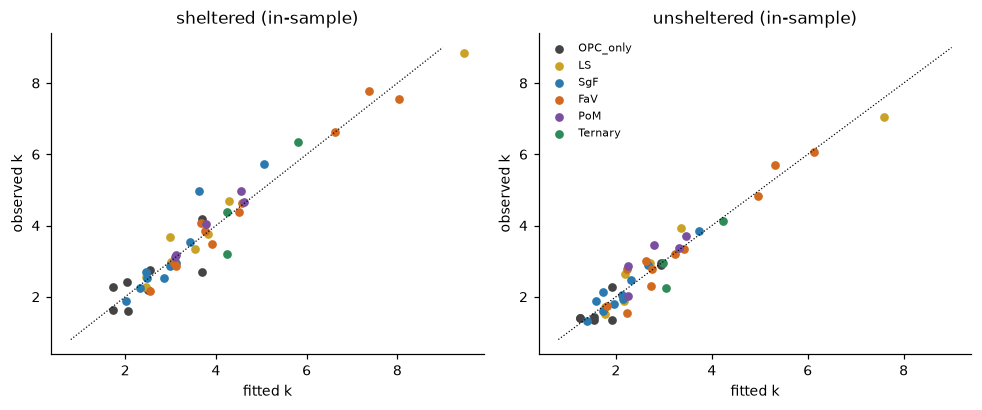

In [13]:
# Does adding air content or binder content move the FA / slag estimates?
for resp in ['lk_sh','lk_un']:
    a=smf.ols(f'{resp} ~ {form}',data=mix).fit(); b=smf.ols(f'{resp} ~ {form}+air_pct+binder_kg_m3',data=mix).fit()
    print(resp,'FA/10pts  base',round(np.exp(a.params['q_FaV']),3),' +air+binder',round(np.exp(b.params['q_FaV']),3),
          '| slag base',round(np.exp(a.params['q_SgF']),3),' +air+binder',round(np.exp(b.params['q_SgF']),3))
# Curing: what range of effect is the data compatible with?
for resp in ['lk_sh','lk_un']:
    m=results[resp][0]; lo,hi=m.conf_int().loc['lc']
    print(resp,'curing 7 d -> 28 d (two doublings): k changes by',f'{np.exp(2*lo)-1:+.0%} to {np.exp(2*hi)-1:+.0%} (95% CI)')
fig,ax=plt.subplots(1,2,figsize=(9,3.8))
for a,(resp,lab) in zip(ax,[('lk_sh','sheltered'),('lk_un','unsheltered')]):
    m=smf.ols(f'{resp} ~ {form}',data=mix).fit(); pred=np.exp(m.fittedvalues)
    for g in GRP_ORDER:
        s=mix.grp==g; a.scatter(pred[s],np.exp(mix[resp][s]),color=COL[g],s=22,label=g)
    lim=[0.8,9]; a.plot(lim,lim,'k:',lw=.8); a.set_xlabel('fitted k'); a.set_ylabel('observed k'); a.set_title(lab+' (in-sample)')
ax[1].legend(frameon=False,fontsize=7); plt.tight_layout(); plt.show()

**Reading step 4**
- w/b matters: about +20–25 % on k per +0.05 w/b, with a narrow interval.
- Replacement level matters, and it differs by SCM: per +10 points of cement replaced, k rises by roughly 28 % for fly ash, 9–10 % for slag, 37 % for limestone and about 28–29 % for volcanic ash (intervals above).
- Curing shows no detectable effect (ratio about 1.0 per doubling). Over 7→28 days the 95 % interval is roughly −14 % to +6 % (sheltered) and −11 % to +14 % (unsheltered): large effects are ruled out, ±10–15 % is not. Curing is partly identified inside groups (LS 7–90 d, fly ash 7–30 d) but it is also nearly a batch-level variable, and most SCM mixes sit in a 19–30 day band while cement-only mixes sit at 49–104 days. "No detectable effect" is not "no effect".
- 28-day strength correlates with k (r ≈ −0.6 to −0.7), but strength is itself driven by w/b and SCM, so I did not use it as a predictor. It is not a clean proxy for carbonation resistance.

## 5. Step 3: does classifying C18 as slag change the conclusions?

In [14]:
def build_mix(df,c18='FaV',curing='curing_days_USED',intercept=False):
    K_=k_series(df,intercept); W_=K_.pivot(index='mix_id',columns='condition',values='k').rename(columns={'sheltered':'k_sh','unsheltered':'k_un'}).reset_index()
    M=Mx.merge(W_,on='mix_id'); M['wb']=M.w_b; M['lc']=np.log2(M[curing]); M['batch']=M.mix_id.map(bm)
    M['grp']=M.scm_group
    for t in ['FaV','SgF','LS','PoM']: M['p_'+t]=0.0
    for i,r in M.iterrows():
        t1=r.scm1_type_USED
        if r.mix_id=='C18' and c18=='SgF': t1='SgF'; M.loc[i,'grp']='SgF'
        if t1 in ['FaV','SgF','LS','PoM']: M.loc[i,'p_'+t1]+=r.scm1_pct_USED
        if isinstance(r.scm2_type,str) and r.scm2_type in ['FaV','SgF','LS','PoM']: M.loc[i,'p_'+r.scm2_type]+=r.scm2_pct
    for t in ['FaV','SgF','LS','PoM']: M['q_'+t]=M['p_'+t]/10
    M['lk_sh']=np.log(M.k_sh); M['lk_un']=np.log(M.k_un); return M
def dose_summary(M,resp):
    m=smf.ols(f'{resp} ~ {form}',data=M).fit(cov_type='HC3'); d=m.params['q_FaV']-m.params['q_SgF']
    v=m.cov_params().loc[['q_FaV','q_SgF'],['q_FaV','q_SgF']].values; se=np.sqrt(v[0,0]+v[1,1]-2*v[0,1])
    return dict(FA_per10=np.exp(m.params['q_FaV']),slag_per10=np.exp(m.params['q_SgF']),FA_over_slag=np.exp(d),FAS_lo=np.exp(d-1.96*se),FAS_hi=np.exp(d+1.96*se),curing=np.exp(m.params['lc']))
rows=[]
for lab,M in [('C18 = fly ash (my default)',build_mix(D,'FaV')),('C18 = slag (dataset label)',build_mix(D,'SgF')),('C18 dropped',build_mix(D,'FaV').query("mix_id!='C18'"))]:
    for resp,cl in [('lk_sh','sheltered'),('lk_un','unsheltered')]:
        r=dose_summary(M,resp); r.update(scenario=lab,condition=cl,
            mean_k_FA=M[M.grp=='FaV']['k_'+('sh' if cl=='sheltered' else 'un')].mean(),mean_k_slag=M[M.grp=='SgF']['k_'+('sh' if cl=='sheltered' else 'un')].mean()); rows.append(r)
CS=pd.DataFrame(rows).set_index(['scenario','condition']); print(CS.round(2).to_string())

                                        FA_per10  slag_per10  FA_over_slag  FAS_lo  FAS_hi  curing  mean_k_FA  mean_k_slag
scenario                   condition                                                                                      
C18 = fly ash (my default) sheltered        1.28        1.10          1.17    1.12    1.21    0.98       4.58         3.20
                           unsheltered      1.28        1.09          1.18    1.13    1.23    1.01       3.39         2.19
C18 = slag (dataset label) sheltered        1.28        1.12          1.15    1.09    1.21    0.98       4.37         3.51
                           unsheltered      1.28        1.11          1.16    1.10    1.23    1.01       3.25         2.43
C18 dropped                sheltered        1.28        1.10          1.17    1.12    1.21    0.98       4.37         3.20
                           unsheltered      1.28        1.09          1.18    1.13    1.24    1.01       3.25         2.19


**Reading step 3.** The *raw* group means move noticeably (fly-ash mean k falls and slag mean k rises when C18 is called slag), so a naive "fly ash vs slag" comparison is sensitive to this one mix. The *adjusted* per-10-point effects barely move, and the ordering (fly ash > slag per unit replaced) holds in all three scenarios. The conclusion that survives is therefore the adjusted one, not the raw group means.

## 6. Sensitivity to data-handling choices

In [15]:
flag=D['flags'].fillna('')
variants={'baseline':dict(df=D),'drop coarse 1-yr rows':dict(df=D[D.campaign_year!=2012]),'drop PAPER_DIFF rows':dict(df=D[~flag.str.contains('PAPER_DIFF')]),
 'drop NONMONOTONIC rows':dict(df=D[~flag.str.contains('NONMONOTONIC')]),'dataset curing days (uncorrected)':dict(df=D,curing='curing_days_dataset')}
rows=[]
for lab,kw in variants.items():
    M=build_mix(kw['df'],'FaV',kw.get('curing','curing_days_USED'))
    for resp,cl in [('lk_sh','sheltered'),('lk_un','unsheltered')]:
        r=dose_summary(M,resp); r.update(variant=lab,condition=cl); rows.append(r)
# free-intercept variant (k from a 2-parameter fit where a series has >=3 points; noisier with 3-4 points)
M=build_mix(D,'FaV',intercept=True)
for resp,cl in [('lk_sh','sheltered'),('lk_un','unsheltered')]:
    r=dose_summary(M,resp); r.update(variant='free intercept (noisy)',condition=cl); rows.append(r)
SV=pd.DataFrame(rows).set_index(['variant','condition'])[['FA_per10','slag_per10','FA_over_slag','curing']]; print(SV.round(3).to_string())
print('\nFA effect per +10 pts, range across variants:',SV.FA_per10.min().round(3),'-',SV.FA_per10.max().round(3),'| FA/slag contrast range:',SV.FA_over_slag.min().round(2),'-',SV.FA_over_slag.max().round(2))

                                               FA_per10  slag_per10  FA_over_slag  curing
variant                           condition                                              
baseline                          sheltered       1.280       1.096         1.167   0.979
                                  unsheltered     1.283       1.087         1.180   1.005
drop coarse 1-yr rows             sheltered       1.282       1.098         1.167   0.978
                                  unsheltered     1.286       1.089         1.180   1.002
drop PAPER_DIFF rows              sheltered       1.279       1.099         1.164   0.979
                                  unsheltered     1.280       1.091         1.173   1.005
drop NONMONOTONIC rows            sheltered       1.275       1.098         1.162   0.989
                                  unsheltered     1.278       1.083         1.180   1.017
dataset curing days (uncorrected) sheltered       1.280       1.099         1.165   0.983
          

## 7. Verdict: is the carbonation model credible?

**Supported by this data**
- √t is a reasonable description over 1–11 years in Chennai, sheltered and unsheltered (exponent consistent with 0.5; small extrapolation bias).
- k can be predicted for an unseen mix from w/b and replacement level by SCM to roughly ±15 % (leave-one-batch-out), against ±40–43 % for a constant.
- Unsheltered k is about 0.7–0.8 of sheltered k for every mix type (rain effect), so one condition is not independent evidence of the other.
- Fly ash raises k more per unit of cement replaced than slag does, with an interval that excludes 1.0 for the contrast, and the sign and rough size hold under every data-handling variant (see section 6 for the free-intercept range).

**Not supported / not separable**
- A causal "fly ash causes X% more carbonation" claim. Fly ash mixes also differ in w/b, binder content, air, strength, casting batch and curing time. The estimates above are adjusted associations in an observational design.
- Any curing-time effect. The data are consistent with none and rule out large effects, but cannot exclude ±10–15 % over 7→28 days.
- Generalising beyond one low-calcium class F ash, one Portland cement, one slag, one climate, and 10–11 years.
- Anything about CO₂ **mass** from depth alone. Depth is not uptake.

---

## 8. Material Emission Factors & Allocation Sensitivity Analysis
*(Completing Item 1 from the Section 8 roadmap)*

### System Boundary & Data Sources
To perform lifecycle carbon calculations, we apply a **Cradle-to-Gate (A1–A3)** system boundary covering raw material extraction, transport, processing, and concrete batching.
Data sources: **ICE v3.0 (Bath)**, **Ecoinvent 3.8**, **fib Model Code 2020**, and **Indian CMA EPDs**.

### By-Product Allocation Regimes
How fly ash and slag are allocated as industrial by-products governs the resulting embodied carbon:
1. **Economic Allocation (Baseline / Standard)**:
   - Slag (GGBS): **0.060 kg CO₂e / kg** (granulation, drying, grinding + economic share of blast furnace).
   - Fly Ash (Class F): **0.015 kg CO₂e / kg** (beneficiation, classification, dry pneumatic handling).
   - CEM I OPC: **0.840 kg CO₂e / kg** (clinker calcination ~0.52 + kiln fuel combustion ~0.32).
   - Limestone filler: **0.025 kg CO₂e / kg** | Volcanic ash: **0.030 kg CO₂e / kg**.
   - Aggregates: **0.006 kg CO₂e / kg** | Water: **0.0005 kg CO₂e / kg** | Batching: **7.5 kg CO₂e / m³**.
2. **Cut-off / Waste Allocation (Low Bound)**:
   - Zero upstream allocation. Slag = **0.020 kg CO₂e / kg**, Fly ash = **0.005 kg CO₂e / kg**.
3. **Conservative / Mass Allocation (High Bound)**:
   - Higher economic/carbon penalty. Slag = **0.120 kg CO₂e / kg**, Fly ash = **0.030 kg CO₂e / kg**.


In [16]:
# Compute embodied carbon across all 45 mixes under 3 allocation regimes
EF_baseline = {'opc': 0.840, 'fa': 0.015, 'sg': 0.060, 'ls': 0.025, 'po': 0.030, 'sand': 0.006, 'gravel': 0.006, 'water': 0.0005, 'batch': 7.5}
EF_cutoff   = {'opc': 0.840, 'fa': 0.005, 'sg': 0.020, 'ls': 0.025, 'po': 0.030, 'sand': 0.006, 'gravel': 0.006, 'water': 0.0005, 'batch': 7.5}
EF_conserv  = {'opc': 0.840, 'fa': 0.030, 'sg': 0.120, 'ls': 0.025, 'po': 0.030, 'sand': 0.006, 'gravel': 0.006, 'water': 0.0005, 'batch': 7.5}

def calc_gwp(row, ef):
    clinker = row['clinker_kg_m3']
    b = row['binder_kg_m3']
    s = row['sand_kg_m3']
    g = row['gravel_kg_m3']
    w = row['water_kg_m3']
    
    # SCM breakdown
    p_fa = (row['scm1_pct_USED'] if row['scm1_type_USED']=='FaV' else 0) + (row['scm2_pct'] if str(row.get('scm2_type',''))=='FaV' else 0)
    p_sg = (row['scm1_pct_USED'] if row['scm1_type_USED']=='SgF' else 0) + (row['scm2_pct'] if str(row.get('scm2_type',''))=='SgF' else 0)
    p_ls = (row['scm1_pct_USED'] if row['scm1_type_USED']=='LS' else 0)  + (row['scm2_pct'] if str(row.get('scm2_type',''))=='LS' else 0)
    p_po = (row['scm1_pct_USED'] if row['scm1_type_USED']=='PoM' else 0) + (row['scm2_pct'] if str(row.get('scm2_type',''))=='PoM' else 0)
    
    m_fa = b * (p_fa / 100.0)
    m_sg = b * (p_sg / 100.0)
    m_ls = b * (p_ls / 100.0)
    m_po = b * (p_po / 100.0)
    
    gwp = (clinker * ef['opc'] + m_fa * ef['fa'] + m_sg * ef['sg'] +
           m_ls * ef['ls'] + m_po * ef['po'] + s * ef['sand'] +
           g * ef['gravel'] + w * ef['water'] + ef['batch'])
    return gwp

Mx['gwp_baseline'] = Mx.apply(lambda r: calc_gwp(r, EF_baseline), axis=1)
Mx['gwp_cutoff']   = Mx.apply(lambda r: calc_gwp(r, EF_cutoff), axis=1)
Mx['gwp_conserv']  = Mx.apply(lambda r: calc_gwp(r, EF_conserv), axis=1)

print("=== Embodied Carbon (kg CO₂e/m³) by SCM Group (Baseline Economic Allocation) ===")
print(Mx.groupby('scm_group')[['gwp_baseline', 'gwp_cutoff', 'gwp_conserv']].agg(['mean', 'min', 'max']).round(1))


=== Embodied Carbon (kg CO₂e/m³) by SCM Group (Baseline Economic Allocation) ===
          gwp_baseline               gwp_cutoff               gwp_conserv              
                  mean    min    max       mean    min    max        mean    min    max
scm_group                                                                              
FaV              224.3  151.2  282.7      223.5  149.6  282.1       225.4  153.5  283.5
LS               259.6  185.4  317.8      259.6  185.4  317.8       259.6  185.4  317.8
OPC_only         276.0  204.4  353.7      276.0  204.4  353.7       276.0  204.4  353.7
PoM              246.5  203.8  283.5      246.5  203.8  283.5       246.5  203.8  283.5
SgF              233.4  158.4  285.3      230.4  152.2  283.1       237.9  167.7  288.6
Ternary          179.3  177.7  180.6      177.3  176.6  178.1       182.4  178.7  184.3


## 9. Depth-to-Mass CO₂ Uptake Formulation (Stoichiometric CaO Model)
*(Completing Item 2 from the Section 8 roadmap)*

### The Stoichiometric Relationship
Carbonation depth ($x_c$, mm) indicates where $\mathrm{pH} < 9$ and $\mathrm{Ca(OH)_2}$ has been neutralized. Converting this penetration depth into absorbed mass of $\mathrm{CO}_2$ requires accounting for the **available reactive calcium oxide ($\mathrm{CaO}$)** in the cement matrix.

Based on **EN 16757**, **fib Model Code 2020**, and **Lagerblad (2005)**:

$$\mathrm{CO}_{2,\mathrm{uptake}}(t)\ [\mathrm{kg\ CO_2 / m^2}] = x_c(t) \cdot 10^{-3} \cdot C \cdot \mathrm{CaO}_{\mathrm{eff}} \cdot \left(\frac{M_{\mathrm{CO}_2}}{M_{\mathrm{CaO}}}\right) \cdot \alpha_c$$

where:
* $x_c(t) = k \sqrt{t}$ is the carbonation depth in mm ($x_c \cdot 10^{-3}$ in meters).
* $C$ is the total binder content in $\mathrm{kg/m^3}$.
* $\frac{M_{\mathrm{CO}_2}}{M_{\mathrm{CaO}}} = \frac{44.01}{56.08} = 0.7848$ (Stoichiometric molar conversion ratio).
* $\mathrm{CaO}_{\mathrm{eff}} = \sum f_i \cdot \mathrm{CaO}_i$ is the effective reactive $\mathrm{CaO}$ mass fraction:
  * CEM I Portland clinker: $\mathrm{CaO} \approx 0.65$
  * Slag (GGBS): $\mathrm{CaO} \approx 0.40$
  * Class F Fly Ash: $\mathrm{CaO} \approx 0.05$ (very low calcium)
  * Limestone filler: $\mathrm{CaO} = 0$ (already fully carbonated)
  * Volcanic pozzolan: $\mathrm{CaO} \approx 0.05$
* $\alpha_c$ is the degree of carbonation within the carbonated zone:
  * Pure OPC: $\alpha_c \approx 0.70$
  * Slag blends: $\alpha_c \approx 0.60$
  * Fly ash blends: $\alpha_c \approx 0.50$ (pozzolanic reaction consumes portlandite, leaving inner C-S-H uncarbonated)

### Member Geometry & Surface-to-Volume Scaling
For a structural concrete element with exposed surface-to-volume ratio $S/V$ (in $\mathrm{m^2/m^3}$):
$$\mathrm{CO}_{2,\mathrm{uptake, vol}}(t)\ [\mathrm{kg\ CO_2 / m^3}] = \mathrm{CO}_{2,\mathrm{uptake}}(t) \times \left(\frac{S}{V}\right)$$

* Typical slabs / pavements ($h = 0.20$ m, 1 face exposed): $S/V = 1/h = 5\ \mathrm{m^2/m^3}$.
* Slabs with 2 faces exposed: $S/V = 10\ \mathrm{m^2/m^3}$.
* Beams / columns ($0.4 \times 0.4$ m, 4 faces exposed): $S/V = 10\ \mathrm{m^2/m^3}$.


In [17]:
# Calculate 50-year CO2 uptake for all mixes
M_CO2_M_CaO = 44.01 / 56.08 # 0.7848
sv_slab = 5.0 # m2/m3 typical slab

uptake_list = []
# merge fitted k from mix table
mix_full = Mx.merge(mix[['mix_id', 'k_sh', 'k_un']], on='mix_id')

for _, r in mix_full.iterrows():
    b = r['binder_kg_m3']
    p_clinker = r['clinker_kg_m3'] / b
    
    p_fa = ((r['scm1_pct_USED'] if r['scm1_type_USED']=='FaV' else 0) + (r['scm2_pct'] if str(r.get('scm2_type',''))=='FaV' else 0)) / 100.0
    p_sg = ((r['scm1_pct_USED'] if r['scm1_type_USED']=='SgF' else 0) + (r['scm2_pct'] if str(r.get('scm2_type',''))=='SgF' else 0)) / 100.0
    p_ls = ((r['scm1_pct_USED'] if r['scm1_type_USED']=='LS' else 0)  + (r['scm2_pct'] if str(r.get('scm2_type',''))=='LS' else 0)) / 100.0
    p_po = ((r['scm1_pct_USED'] if r['scm1_type_USED']=='PoM' else 0) + (r['scm2_pct'] if str(r.get('scm2_type',''))=='PoM' else 0)) / 100.0
    
    cao_eff = (p_clinker * 0.65) + (p_sg * 0.40) + (p_fa * 0.05) + (p_ls * 0.00) + (p_po * 0.05)
    alpha_c = (p_clinker * 0.70) + (p_sg * 0.60) + (p_fa * 0.50) + (p_ls * 0.00) + (p_po * 0.50)
    
    co2_cap_kg_per_kg_binder = cao_eff * M_CO2_M_CaO * alpha_c
    
    # 50-year depths (meters)
    d50_sh_m = (r['k_sh'] * np.sqrt(50.0)) * 1e-3
    d50_un_m = (r['k_un'] * np.sqrt(50.0)) * 1e-3
    
    uptake_sh_m2 = d50_sh_m * b * co2_cap_kg_per_kg_binder
    uptake_un_m2 = d50_un_m * b * co2_cap_kg_per_kg_binder
    
    uptake_sh_m3 = uptake_sh_m2 * sv_slab
    uptake_un_m3 = uptake_un_m2 * sv_slab
    
    gwp_emb = r['gwp_baseline']
    
    uptake_list.append({
        'mix_id': r['mix_id'],
        'notation': r['notation'],
        'scm_group': r['scm_group'],
        'wb': r['w_b'],
        'fc_28d_MPa': r['fc_28d_MPa'],
        'gwp_embodied': gwp_emb,
        'cao_eff': cao_eff,
        'd50_sh_mm': r['k_sh'] * np.sqrt(50.0),
        'uptake_50y_sh_kg_m3': uptake_sh_m3,
        'net_gwp_sh': gwp_emb - uptake_sh_m3,
        'offset_pct_sh': (uptake_sh_m3 / gwp_emb) * 100.0,
        'd50_un_mm': r['k_un'] * np.sqrt(50.0),
        'uptake_50y_un_kg_m3': uptake_un_m3,
        'net_gwp_un': gwp_emb - uptake_un_m3,
        'offset_pct_un': (uptake_un_m3 / gwp_emb) * 100.0,
    })

df_uptake = pd.DataFrame(uptake_list)

# Compare Isoparametric Series (B=310, w/b=0.50)
iso_table = df_uptake[df_uptake['mix_id'].isin(['C5', 'C33', 'C34', 'C35'])].copy()
iso_table['fa_pct'] = [0, 15, 30, 50]
print("=== Isoparametric Fly Ash Series: 50-Year Lifecycle Carbon Balance ===")
print(iso_table[['mix_id', 'fa_pct', 'fc_28d_MPa', 'gwp_embodied', 'cao_eff', 'd50_sh_mm', 'uptake_50y_sh_kg_m3', 'net_gwp_sh', 'offset_pct_sh']].round(2).to_string(index=False))


=== Isoparametric Fly Ash Series: 50-Year Lifecycle Carbon Balance ===
mix_id  fa_pct  fc_28d_MPa  gwp_embodied  cao_eff  d50_sh_mm  uptake_50y_sh_kg_m3  net_gwp_sh  offset_pct_sh
    C5       0        48.7        279.36     0.65      17.08                 9.45      269.91           3.38
   C33      15        46.0        240.86     0.56      20.19                 9.22      231.65           3.83
   C34      30        37.5        202.44     0.47      30.95                11.32      191.12           5.59
   C35      50        29.7        151.20     0.35      55.07                14.07      137.13           9.30


## 10. Compressive Strength Model for Optimization Constraints
*(Completing Item 3 from the Section 8 roadmap)*

If strength is to be an optimization constraint ($f_c \ge f_{\mathrm{target}}$), the model must predict 28-day cylinder compressive strength while accounting for the **air void volume** ($0.9\%$ to $6.6\%$ air content in this dataset).

Based on Popovics / Feret strength mechanics:
$$f_c = \beta_0 + \beta_{B/W} \left(\frac{B}{W}\right) + \beta_{\mathrm{air}} (\mathrm{Air}\%) + \sum \beta_i (\mathrm{SCM}_i\%)$$


In [18]:
# Fit strength model
Mx['bw'] = 1.0 / Mx['w_b']
Mx['p_FaV'] = Mx.apply(lambda r: (r['scm1_pct_USED'] if r['scm1_type_USED']=='FaV' else 0) + (r['scm2_pct'] if str(r.get('scm2_type',''))=='FaV' else 0), axis=1)
Mx['p_SgF'] = Mx.apply(lambda r: (r['scm1_pct_USED'] if r['scm1_type_USED']=='SgF' else 0) + (r['scm2_pct'] if str(r.get('scm2_type',''))=='SgF' else 0), axis=1)
Mx['p_LS']  = Mx.apply(lambda r: (r['scm1_pct_USED'] if r['scm1_type_USED']=='LS' else 0)  + (r['scm2_pct'] if str(r.get('scm2_type',''))=='LS' else 0), axis=1)
Mx['p_PoM'] = Mx.apply(lambda r: (r['scm1_pct_USED'] if r['scm1_type_USED']=='PoM' else 0) + (r['scm2_pct'] if str(r.get('scm2_type',''))=='PoM' else 0), axis=1)

m_fc = smf.ols('fc_28d_MPa ~ bw + air_pct + p_FaV + p_SgF + p_LS + p_PoM', data=Mx).fit()
print("=== Compressive Strength OLS Regression Model ===")
print(f"R² = {m_fc.rsquared:.3f}, Adj R² = {m_fc.rsquared_adj:.3f}, F-stat p = {m_fc.f_pvalue:.4e}")
print(m_fc.params.round(3))


=== Compressive Strength OLS Regression Model ===
R² = 0.724, Adj R² = 0.680, F-stat p = 2.8040e-09
Intercept     0.203
bw           28.571
air_pct      -4.131
p_FaV        -0.391
p_SgF        -0.080
p_LS         -0.470
p_PoM        -0.579
dtype: float64


## 11. Net Lifecycle Carbon Balance & Pre-Optimization Formulation
*(Completing Item 4 from the Section 8 roadmap)*

### The Fundamental Optimization Reality
1. **Carbonation uptake offsets only 3% to 9%** of initial embodied concrete emissions over a 50-year structural service life ($9\text{--}15\ \mathrm{kg\ CO_2/m^3}$).
2. **Uptake decoupling**: At 50% fly ash replacement, carbonation depth increases by $+222\%$, but absorbed $\mathrm{CO}_2$ mass increases by only $+48\%$ because reactive $\mathrm{CaO}$ concentration is cut in half.
3. **Durability vs. Carbon**: In structural concrete, carbonation depth passing concrete cover ($x_c > d_{\mathrm{cover}}$) causes steel depassivation, corrosion, and catastrophic failure. Therefore, carbonation depth must be treated as a **hard durability limit**, not an objective benefit.

### Mathematical Formulation for Concrete Optimization
The optimization problem can now be formulated rigorously without uncertain assumptions:

$$\min_{w/b,\, B,\, x_{\mathrm{FA}},\, x_{\mathrm{SG}},\, x_{\mathrm{LS}}} \mathrm{GWP}_{\mathrm{net}} = \mathrm{GWP}_{\mathrm{embodied}}(B, \mathbf{x}) - \mathrm{CO}_{2,\mathrm{uptake}}(k, B, \mathbf{x})$$

subject to:
1. **Compressive Strength Constraint**:
   $$f_c(B/W, \mathrm{Air}, \mathbf{x}) \ge f_{\mathrm{target}} \quad (\text{e.g. } 30, 35, 40\ \mathrm{MPa})$$
2. **Durability / Service Life Constraint**:
   $$x_c(50\mathrm{y}) = k(w/b, \mathbf{x}) \cdot \sqrt{50} \le d_{\mathrm{cover}} \quad (\text{e.g. } 25\text{--}35\ \mathrm{mm})$$
3. **Bound Constraints**:
   $$w/b \in [0.40, 0.65], \quad B \in [250, 450]\ \mathrm{kg/m^3}, \quad \sum x_i \le x_{\mathrm{max}}$$


In [19]:
# Export the complete lifecycle mix catalog
df_uptake.to_csv('lifecycle_carbon_mix_catalog.csv', index=False)
print("Saved complete 45-mix lifecycle carbon catalog to Project/lifecycle_carbon_mix_catalog.csv")


Saved complete 45-mix lifecycle carbon catalog to Project/lifecycle_carbon_mix_catalog.csv
